JS04 Praktikum 3 - DBSCAN pada dataset sintetis make_blobs.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("dbscan.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js04-klasterisasi\praktikum-3


In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from sklearn import metrics
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(exist_ok=True)

X.shape: (750, 2)


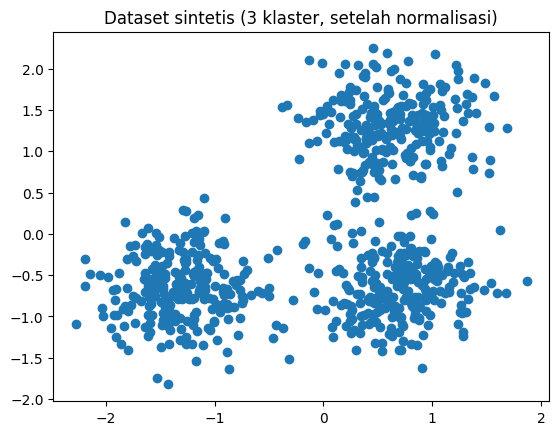

In [3]:
# 1. Dataset sintetis: 3 klaster
centers = [[1, 1], [-1, -1], [1, -1]]
X, labels_true = make_blobs(n_samples=750, centers=centers, cluster_std=0.4, random_state=0)
X = StandardScaler().fit_transform(X)
print("X.shape:", X.shape)

plt.scatter(X[:, 0], X[:, 1])
plt.title("Dataset sintetis (3 klaster, setelah normalisasi)")
plt.savefig(OUT / "01_dataset.png", dpi=120, bbox_inches="tight")

In [4]:
# 2. DBSCAN
db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)
print(f"Estimated number of clusters: {n_clusters_}")
print(f"Estimated number of noise points: {n_noise_}")

Estimated number of clusters: 3
Estimated number of noise points: 18


In [5]:
# 3. Evaluasi
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}")

Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916


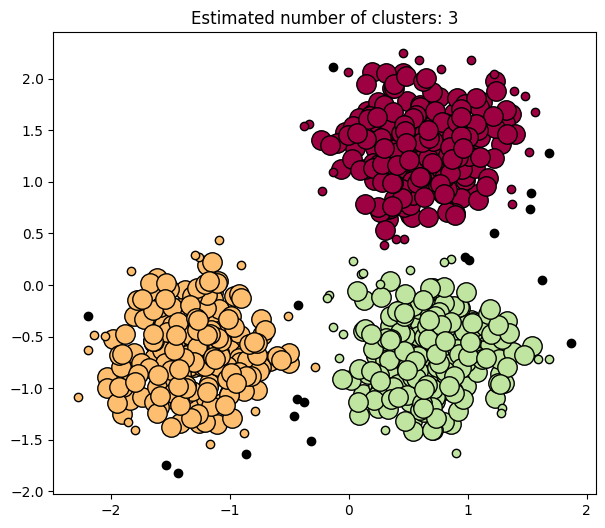

In [6]:
# 4. Visualisasi: core besar, non-core kecil, noise hitam
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

plt.figure(figsize=(7, 6))
for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]  # noise hitam
    member = labels == k
    xy = X[member & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col),
             markeredgecolor="k", markersize=14)
    xy = X[member & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], "o", markerfacecolor=tuple(col),
             markeredgecolor="k", markersize=6)

plt.title(f"Estimated number of clusters: {n_clusters_}")
plt.savefig(OUT / "02_dbscan.png", dpi=120, bbox_inches="tight")

In [7]:
# 5. Eksperimen parameter -> tabel
print(f"\n{'eps':>5} {'min_samples':>12} {'klaster':>8} {'noise':>6} {'ARI':>6} {'Silhouette':>11}")
sil = lambda L: metrics.silhouette_score(X, L) if len(set(L) - {-1}) > 1 else float("nan")
for eps in (0.05, 0.1, 0.3, 0.5):
    for min_samples in (3, 10, 20):
        L = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
        n_c = len(set(L)) - (1 if -1 in L else 0)
        print(f"{eps:>5} {min_samples:>12} {n_c:>8} {list(L).count(-1):>6} "
              f"{metrics.adjusted_rand_score(labels_true, L):>6.3f} {sil(L):>11.3f}")


  eps  min_samples  klaster  noise    ARI  Silhouette
 0.05            3       73    420  0.008      -0.236
 0.05           10        0    750  0.000         nan
 0.05           20        0    750  0.000         nan
  0.1            3       26    145  0.393      -0.123
  0.1           10       12    516  0.024      -0.366
  0.1           20        0    750  0.000         nan
  0.3            3        2      4  0.000      -0.082
  0.3           10        3     18  0.952       0.626
  0.3           20        3     46  0.894       0.596
  0.5            3        1      0  0.000         nan
  0.5           10        1      0  0.000         nan
  0.5           20        1      0  0.000         nan
